# HanuAI ML Assessment - Task 1: Web Scraping and Sentiment Analysis

**Goal:** collect public product reviews from BestBuy.ca, run (aspect-based) sentiment analysis, and turn the results into business insights.

**Notebook map**

| Part | What it does |
|---|---|
| 0 | Configuration (the only cell you must edit) |
| 1 | Imports, helper functions, retry logic, robots.txt check |
| 2 | Scraping - Method A: Selenium (click "Show More", apply filters) |
| 3 | Scraping - Method B: JSON endpoint via `requests` (faster alternative) |
| 4 | Cleaning: primary key, YYYY-MM-DD dates, de-duplication |
| 5 | Sentiment analysis (VADER + rating blend + aspect tags) |
| 6 | Export to CSV / Excel |
| 7 | Visual analysis and business insights |
| 8 | Anti-scraping challenges and solutions (for the report) |

**Compliance:** only public review data is collected, no login, polite random delays, and robots.txt is checked. BestBuy's bot protection blocked the automated Selenium browser ("Access Denied"), so that block was respected and the public review pages were saved from a normal browser session (Ctrl+S -> Webpage, Complete) and parsed here.

**How to run:** put the saved page(s) in the `saved_pages/` folder, then **Restart -> Run All**.

## Part 0 - Configuration (edit this cell)

In [1]:
import re, os
from pathlib import Path

# Product analysed: Samsung Essential F320 27in monitor (>= 50 reviews). The SKU is the number at the end of the URL.
PRODUCT_URL = "https://www.bestbuy.ca/en-ca/product/samsung-essential-f320-27-1080p-hd-ips-led-monitor-ls27f320ganxza-flicker-free-blue-light-120hz/19277986"

# 2) Which scraping method to run: "selenium", "api", or "both" (both = merge and de-duplicate)
SCRAPE_METHOD = "saved_pages"   # reviews are parsed from pages saved in a normal browser (see Part 3b)

# 3) Filters required by the assignment. Each one is applied in turn, then results are merged.
SORT_FILTERS = ["Most Relevant", "Most Helpful", "Newest", "Highest Rating", "Lowest Rating"]
STAR_FILTERS = [None]          # None = all stars. To squeeze out more reviews use [None, 5, 4, 3, 2, 1]

# 4) Behaviour
HEADLESS = False               # False = you can watch the browser (recommended while debugging)
MAX_SHOW_MORE_CLICKS = 80      # safety cap per filter
DELAY_RANGE = (2.0, 5.0)       # random pause (seconds) between actions -> polite, human-like
MAX_RETRIES = 3
USE_TRANSFORMER = False        # True = also run a RoBERTa model (slower, needs `transformers` + `torch`)

# 5) For the API method (Part 3): paste the review URL you find in Chrome DevTools > Network.
#    Use {page} where the page number goes. Leave "" to skip.
API_URL_TEMPLATE = ""
API_MAX_PAGES = 50

# Outputs
OUT_DIR = Path("data");   OUT_DIR.mkdir(exist_ok=True)
CHART_DIR = Path("charts"); CHART_DIR.mkdir(exist_ok=True)

SKU_MATCH = re.search(r"/(\d{6,10})(?:[/?#]|$)", PRODUCT_URL)
SKU = SKU_MATCH.group(1) if SKU_MATCH else None
print("SKU:", SKU)

SKU: 19277986


## Part 1 - Imports and helper functions

* `polite_sleep` - random delay so traffic does not look like a bot.
* `retry` - decorator that re-tries a failing step with exponential back-off (anti-blocking mitigation #1).
* `check_robots` - reads robots.txt so we can document that scraping respects the site policy.
* `parse_date` - converts every date style ("2024-03-05", "Mar 5, 2024", "3 months ago") into **YYYY-MM-DD**.

In [2]:
import time, random, json, hashlib, functools, warnings
from datetime import datetime, timedelta
from urllib.robotparser import RobotFileParser
from urllib.parse import urlparse

import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 90)
sns.set_theme(style="whitegrid")

UA = ("Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 "
      "(KHTML, like Gecko) Chrome/124.0 Safari/537.36")

def polite_sleep(lo=None, hi=None):
    lo, hi = lo or DELAY_RANGE[0], hi or DELAY_RANGE[1]
    time.sleep(random.uniform(lo, hi))

def retry(max_tries=MAX_RETRIES, base_delay=3.0):
    # Exponential back-off: wait 3s, 6s, 12s ... between attempts.
    def deco(fn):
        @functools.wraps(fn)
        def wrapper(*a, **kw):
            for attempt in range(1, max_tries + 1):
                try:
                    return fn(*a, **kw)
                except Exception as e:
                    if attempt == max_tries:
                        raise
                    wait = base_delay * 2 ** (attempt - 1) + random.random()
                    print(f"[retry] {fn.__name__} failed ({type(e).__name__}: {str(e)[:80]}). "
                          f"Attempt {attempt}/{max_tries}, waiting {wait:.1f}s")
                    time.sleep(wait)
        return wrapper
    return deco

def check_robots(url):
    # Documents compliance: is our target path allowed for generic crawlers? (timeout prevents hanging)
    p = urlparse(url)
    robots_url = f"{p.scheme}://{p.netloc}/robots.txt"
    try:
        r = requests.get(robots_url, headers={"User-Agent": UA}, timeout=10)
        if r.status_code != 200:
            print(f"robots.txt returned HTTP {r.status_code}. Read it manually: {robots_url}")
            return None
        rp = RobotFileParser(); rp.parse(r.text.splitlines())
        allowed = rp.can_fetch("*", url)
        print(f"robots.txt allows generic crawler to fetch this URL: {allowed}")
        return allowed
    except Exception as e:
        print("Could not read robots.txt (read it manually in your browser):", type(e).__name__)
        return None

_REL = re.compile(r"(?i)(\d+|a|an)\s+(second|minute|hour|day|week|month|year)s?\s+ago")
_UNIT_DAYS = {"second": 0, "minute": 0, "hour": 0, "day": 1, "week": 7, "month": 30, "year": 365}

def parse_date(value):
    # Returns 'YYYY-MM-DD' or None.
    if value is None or (isinstance(value, float) and np.isnan(value)):
        return None
    s = str(value).strip()
    m = _REL.search(s)
    if m:                                    # relative dates: "3 months ago"
        n = 1 if m.group(1).lower() in ("a", "an") else int(m.group(1))
        return (datetime.now() - timedelta(days=n * _UNIT_DAYS[m.group(2).lower()])).strftime("%Y-%m-%d")
    if s.lower() in ("today", "just now"):
        return datetime.now().strftime("%Y-%m-%d")
    if s.lower() == "yesterday":
        return (datetime.now() - timedelta(days=1)).strftime("%Y-%m-%d")
    if re.fullmatch(r"\d{10,13}", s):        # unix timestamp (s or ms)
        ts = int(s) / (1000 if len(s) == 13 else 1)
        return datetime.fromtimestamp(ts).strftime("%Y-%m-%d")
    dt = pd.to_datetime(re.sub(r"(?i)^(posted|reviewed)( on)?:?\s*", "", s), errors="coerce")
    return None if pd.isna(dt) else dt.strftime("%Y-%m-%d")

print(parse_date("2024-03-05"), parse_date("Mar 5, 2024"), parse_date("3 months ago"))
check_robots(PRODUCT_URL)

2024-03-05 2024-03-05 2026-07-27
Could not read robots.txt (read it manually in your browser): ReadTimeout


## Part 2 - Scraping Method A: Selenium (the method the assignment describes)

**Flow per filter:** open product page -> dismiss cookie banner -> open the Reviews section -> choose the sort filter ->
click **Show More** until no new reviews appear -> parse every review card.

> **Important:** Best Buy can change its HTML. If a field comes back empty, run the *Selector inspector* cell below
> while the browser is open, then update the `SELECTORS` dictionary. Each field has a *list* of fallback selectors
> (tried in order) so small layout changes do not break the scraper.

In [3]:
from selenium import webdriver
from selenium.webdriver.common.by import By
from selenium.webdriver.support.ui import WebDriverWait, Select
from selenium.webdriver.support import expected_conditions as EC
from selenium.common.exceptions import (TimeoutException, NoSuchElementException,
                                        StaleElementReferenceException,
                                        ElementClickInterceptedException)

# Fallback CSS selectors for each field. Edit after inspecting the live page (F12).
SELECTORS = {
    "card":     ["[data-testid='review-card']", "[class*='reviewItem']", "[class*='review-item']",
                 "[class*='ReviewItem']", "li[class*='review']", "div[class*='review_'][class*='container']"],
    "title":    ["[data-testid='review-title']", "[class*='reviewTitle']", "[class*='review-title']",
                 "h3", "h4"],
    "text":     ["[data-testid='review-text']", "[class*='reviewContent']", "[class*='review-content']",
                 "[class*='reviewText']", "[class*='review-text']"],   # no bare "p": it matched a hidden "Customer rating: N out of 5" label
    "name":     ["[data-testid='reviewer-name']", "[class*='reviewerName']", "[class*='reviewer-name']",
                 "[class*='userName']", "[class*='nickname']", "[class*='author']"],
    "date":     ["time", "[data-testid='review-date']", "[class*='reviewDate']", "[class*='review-date']",
                 "[class*='submissionDate']", "[class*='date']"],
}

def make_driver(headless=HEADLESS, capture_network=False):
    opts = webdriver.ChromeOptions()
    if headless:
        opts.add_argument("--headless=new")
    opts.add_argument("--window-size=1366,900")
    opts.add_argument("--lang=en-CA")
    opts.add_argument(f"user-agent={UA}")
    opts.add_argument("--disable-blink-features=AutomationControlled")
    if capture_network:   # lets us list the XHR/JSON calls the page makes (see Part 3)
        opts.set_capability("goog:loggingPrefs", {"performance": "ALL"})
    try:
        return webdriver.Chrome(options=opts)          # Selenium Manager downloads the driver automatically
    except Exception:
        from selenium.webdriver.chrome.service import Service
        from webdriver_manager.chrome import ChromeDriverManager
        return webdriver.Chrome(service=Service(ChromeDriverManager().install()), options=opts)

def _first(el, selectors, attr=None):
    # Try each selector until one returns text.
    for sel in selectors:
        try:
            node = el.find_element(By.CSS_SELECTOR, sel)
            val = node.get_attribute(attr) if attr else (node.text or node.get_attribute("textContent"))
            val = (val or "").strip()
            if val:
                return val
        except (NoSuchElementException, StaleElementReferenceException):
            continue
    return None

def _rating_from_card(card):
    # Rating is found by regex over the card HTML so it works for aria-labels, hidden text or alt text.
    html = card.get_attribute("outerHTML") or ""
    for pat in (r"(\d(?:\.\d)?)\s*(?:out of|/)\s*5", r"[Rr]ating[^0-9]{0,15}(\d(?:\.\d)?)",
                r"(\d(?:\.\d)?)\s*stars?"):
        m = re.search(pat, html)
        if m and 0 <= float(m.group(1)) <= 5:
            return float(m.group(1))
    return None

def dismiss_banners(driver):
    for txt in ("Accept", "Got it", "I agree", "Close", "No thanks", "Continue"):
        try:
            btn = driver.find_element(By.XPATH, f"//button[contains(normalize-space(.), '{txt}')]")
            if btn.is_displayed():
                btn.click(); time.sleep(0.8)
        except Exception:
            pass

def open_reviews_section(driver):
    # Scroll gradually so lazy-loaded sections render, then click any "Reviews" tab/link if present.
    for _ in range(8):
        driver.execute_script("window.scrollBy(0, document.body.scrollHeight/8);"); time.sleep(0.6)
    for xp in ("//a[contains(translate(., 'REVIEWS', 'reviews'), 'reviews')]",
               "//button[contains(translate(., 'REVIEWS', 'reviews'), 'reviews')]"):
        for el in driver.find_elements(By.XPATH, xp)[:6]:
            try:
                if el.is_displayed() and "review" in el.text.lower():
                    driver.execute_script("arguments[0].scrollIntoView({block:'center'});", el)
                    el.click(); time.sleep(1.5); return
            except Exception:
                continue

def apply_sort(driver, label):
    # Handles both a native <select> and a custom dropdown button + option list.
    if not label:
        return False
    try:
        for sel in driver.find_elements(By.TAG_NAME, "select"):
            opts = [o.text.strip() for o in Select(sel).options]
            if any(label.lower() == o.lower() for o in opts):
                Select(sel).select_by_visible_text(next(o for o in opts if o.lower() == label.lower()))
                time.sleep(2); return True
    except Exception:
        pass
    try:                                         # custom dropdown
        trig = driver.find_elements(By.XPATH, "//*[self::button or @role='combobox'][contains(translate(., 'SORT', 'sort'), 'sort')]")
        if trig:
            driver.execute_script("arguments[0].scrollIntoView({block:'center'});", trig[0]); trig[0].click(); time.sleep(0.8)
        opt = driver.find_element(By.XPATH, f"//*[self::li or self::button or self::option or @role='option'][normalize-space(.)='{label}']")
        driver.execute_script("arguments[0].click();", opt); time.sleep(2); return True
    except Exception:
        print(f"   [warn] could not apply sort filter '{label}' (page layout may differ) - continuing with default order")
        return False

def count_cards(driver):
    for sel in SELECTORS["card"]:
        n = len(driver.find_elements(By.CSS_SELECTOR, sel))
        if n:
            return n, sel
    return 0, None

def click_show_more(driver, max_clicks=MAX_SHOW_MORE_CLICKS):
    xp = ("//button[contains(translate(normalize-space(.), 'SHOWMORE', 'showmore'), 'show more') "
          "or contains(translate(normalize-space(.), 'LOADMORE', 'loadmore'), 'load more')]")
    stalls, clicks = 0, 0
    while clicks < max_clicks and stalls < 2:
        before, _ = count_cards(driver)
        try:
            btn = WebDriverWait(driver, 6).until(EC.presence_of_element_located((By.XPATH, xp)))
            driver.execute_script("arguments[0].scrollIntoView({block:'center'});", btn); time.sleep(0.8)
            try:
                btn.click()
            except ElementClickInterceptedException:
                driver.execute_script("arguments[0].click();", btn)   # JS click bypasses overlays
            clicks += 1; polite_sleep(1.5, 3.0)
        except (TimeoutException, StaleElementReferenceException):
            break                                       # no more button -> everything is loaded
        after, _ = count_cards(driver)
        stalls = stalls + 1 if after <= before else 0
    return clicks

def parse_cards(driver, sort_label, star_label):
    n, card_sel = count_cards(driver)
    rows = []
    if not card_sel:
        return rows
    for card in driver.find_elements(By.CSS_SELECTOR, card_sel):
        try:
            text = _first(card, SELECTORS["text"])
            if not text:
                continue
            date_raw = _first(card, ["time"], "datetime") or _first(card, SELECTORS["date"])
            rows.append({
                "title": _first(card, SELECTORS["title"]),
                "review_text": text,
                "reviewer_name": _first(card, SELECTORS["name"]),
                "date_raw": date_raw,
                "rating": _rating_from_card(card),
                "source": "bestbuy.ca",
                "sort_filter": sort_label, "star_filter": star_label,
            })
        except StaleElementReferenceException:
            continue
    return rows

@retry()
def scrape_one_view(driver, sort_label, star_label):
    driver.get(PRODUCT_URL); polite_sleep(4, 7)
    dismiss_banners(driver); open_reviews_section(driver)
    apply_sort(driver, sort_label)
    # star filter is optional; implemented as a click on a "N stars" filter if it exists
    if star_label:
        try:
            el = driver.find_element(By.XPATH, f"//*[self::button or self::label or self::li][contains(normalize-space(.), '{star_label} star') or contains(@aria-label, '{star_label} star')]")
            driver.execute_script("arguments[0].click();", el); time.sleep(2)
        except Exception:
            print(f"   [warn] star filter {star_label} not found")
    clicks = click_show_more(driver)
    rows = parse_cards(driver, sort_label, star_label)
    print(f"   sort='{sort_label}' stars={star_label}: {clicks} 'Show More' clicks -> {len(rows)} reviews parsed")
    return rows

def scrape_selenium():
    driver = make_driver()
    all_rows = []
    try:
        for s in SORT_FILTERS:
            for st in STAR_FILTERS:
                try:
                    all_rows += scrape_one_view(driver, s, st)
                except Exception as e:
                    print(f"   [error] view sort={s} stars={st} failed: {type(e).__name__}: {str(e)[:100]}")
                polite_sleep()
    finally:
        driver.quit()
    return pd.DataFrame(all_rows)

### Selector inspector (run only when fields come back empty)
Opens the page, scrolls to the reviews, and prints the CSS class names that contain the word "review". Use them to update `SELECTORS`.

In [4]:
def inspect_selectors():
    d = make_driver()
    try:
        d.get(PRODUCT_URL); polite_sleep(4, 6); dismiss_banners(d); open_reviews_section(d)
        html = d.page_source
        classes = re.findall(r'class="([^"]*review[^"]*)"', html, flags=re.I)
        from collections import Counter
        for cls, n in Counter(classes).most_common(25):
            print(f"{n:4d}  .{cls.strip().replace(' ', '.')}")
        testids = set(re.findall(r'data-testid="([^"]*)"', html))
        print("\ndata-testid values containing 'review':", sorted(t for t in testids if 'review' in t.lower()))
    finally:
        input("Press Enter in the notebook to close the browser...")
        d.quit()

# inspect_selectors()   # <- uncomment ONLY when you need to debug selectors

## Part 3 - Scraping Method B: JSON endpoint (fast, stable alternative)

Many sites load reviews from a JSON URL behind the scenes. Calling it directly returns clean fields without any HTML parsing.

**How to find it (2 minutes):**
1. Open the product page in Chrome -> **F12** -> **Network** tab -> filter **Fetch/XHR**.
2. Scroll to reviews and click **Show More**. A new request containing `review` appears.
3. Right-click it -> *Copy -> Copy URL*. Replace the page number with `{page}` and paste into `API_URL_TEMPLATE` (Part 0).

Or run `discover_review_endpoints()` below: it opens the page, loads reviews and prints the matching network calls.
Only call endpoints the public page itself uses, and keep the request rate low.

In [5]:
def discover_review_endpoints():
    d = make_driver(capture_network=True)
    found = []
    try:
        d.get(PRODUCT_URL); polite_sleep(4, 6); dismiss_banners(d); open_reviews_section(d); click_show_more(d, 2)
        for entry in d.get_log("performance"):
            msg = json.loads(entry["message"])["message"]
            if msg.get("method") == "Network.responseReceived":
                r = msg["params"]["response"]
                if "review" in r["url"].lower() and "json" in r.get("mimeType", ""):
                    found.append(r["url"])
    finally:
        d.quit()
    for u in dict.fromkeys(found):
        print(u)
    return found

# discover_review_endpoints()   # <- uncomment to list candidate JSON URLs

# Flexible key mapping: different APIs name the same field differently.
KEYMAP = {
    "title":         ["title", "headline", "reviewTitle", "Title"],
    "review_text":   ["comment", "text", "reviewText", "body", "content", "ReviewText"],
    "rating":        ["rating", "stars", "overallRating", "Rating", "score"],
    "date_raw":      ["submissionTime", "submissionDate", "createdAt", "date", "reviewDate", "SubmissionTime", "created", "postedDate"],
    "reviewer_name": ["userNickname", "reviewerName", "nickname", "author", "userName", "displayName", "UserNickname", "name"],
    "native_id":     ["id", "reviewId", "Id", "ReviewId"],
}

def _find_review_list(obj):
    # Walks the JSON and returns the first list of dicts that looks like reviews.
    if isinstance(obj, list) and obj and isinstance(obj[0], dict):
        keys = set(obj[0].keys())
        if keys & set(KEYMAP["rating"]) and keys & set(KEYMAP["review_text"]):
            return obj
    if isinstance(obj, dict):
        for v in obj.values():
            r = _find_review_list(v)
            if r:
                return r
    if isinstance(obj, list):
        for v in obj:
            r = _find_review_list(v)
            if r:
                return r
    return None

def _pick(rec, names):
    for n in names:
        if n in rec and rec[n] not in (None, ""):
            return rec[n]
    return None

@retry()
def _get_json(url, session):
    r = session.get(url, timeout=25)
    if r.status_code in (403, 429, 503):
        raise RuntimeError(f"HTTP {r.status_code} - blocked/rate-limited")
    r.raise_for_status()
    return r.json()

def scrape_api(template=None, max_pages=API_MAX_PAGES):
    template = template or API_URL_TEMPLATE
    if not template:
        print("API_URL_TEMPLATE is empty - skipping Method B"); return pd.DataFrame()
    session = requests.Session()
    session.headers.update({"User-Agent": UA, "Accept": "application/json", "Accept-Language": "en-CA,en;q=0.9"})
    rows = []
    for page in range(1, max_pages + 1):
        data = _get_json(template.format(page=page), session)
        recs = _find_review_list(data)
        if not recs:
            break
        for rec in recs:
            row = {k: _pick(rec, v) for k, v in KEYMAP.items()}
            row.update(source="bestbuy.ca", sort_filter="api", star_filter=None)
            rows.append(row)
        print(f"   page {page}: +{len(recs)} reviews (total {len(rows)})")
        polite_sleep(1.5, 3.5)
    return pd.DataFrame(rows)

## Part 3b - Load the reviews (saved public pages -> BeautifulSoup)
Because the automated browser was blocked, the public review pages were opened in a **normal browser session**, every review was
loaded with "Show more", and each page was saved with **Ctrl+S -> Webpage, Complete** into `saved_pages/` (one file per sort filter,
e.g. `Newest.html`). This cell parses those files. A review can appear in several files and twice per file (desktop and mobile
layout); duplicates are removed in Part 4.

Some reviews contain a star rating only (no written text). They are kept because the rating is valid data and flagged with `has_text`.

In [6]:
from bs4 import BeautifulSoup

SAVED_DIR = Path("saved_pages"); SAVED_DIR.mkdir(exist_ok=True)
RAW_CSV = OUT_DIR / "bestbuy_reviews_raw.csv"
IS_DEMO = False
PREFIX = ""

JUNK_BODY = re.compile(r"customer rating.{0,6}\d(?:\.\d)?\s*out of\s*5", re.I)   # hidden accessibility label

def _bs_first(el, selectors, attr=None):
    for sel in selectors:
        for node in el.select(sel):
            val = node.get(attr) if attr else node.get_text(" ", strip=True)
            if val and str(val).strip():
                return str(val).strip()
    return None

def _body_text(c):
    # Review body = first non-empty text from the body selectors that is not the hidden rating label.
    for sel in SELECTORS["text"]:
        for node in c.select(sel):
            val = node.get_text(" ", strip=True)
            if val and not (JUNK_BODY.search(val) and len(val) < 60):
                return val
    return ""

def _rating_from_html(html):
    for pat in (r"(\d(?:\.\d)?)\s*(?:out of|/)\s*5", r"[Rr]ating[^0-9]{0,15}(\d(?:\.\d)?)",
                r"(\d(?:\.\d)?)\s*stars?"):
        m = re.search(pat, html)
        if m and 0 <= float(m.group(1)) <= 5:
            return float(m.group(1))
    return None

def _date_from_card(c):
    # Review date appears in the card text after the reviewer name, e.g. "- August 24, 2026"
    m = re.search(r"-\s*([A-Z][a-z]+\.?\s+\d{1,2},\s+\d{4})", c.get_text(" ", strip=True))
    return m.group(1) if m else None

def inspect_saved_html():
    # Debug helper: prints the class names containing "review" if the selectors stop matching.
    from collections import Counter
    files = sorted(SAVED_DIR.glob("*.htm*"))
    if not files:
        print("No .html files found in", SAVED_DIR.resolve()); return
    html = files[0].read_text(encoding="utf-8", errors="ignore")
    for cls, n in Counter(re.findall(r'class="([^"]*review[^"]*)"', html, flags=re.I)).most_common(25):
        print(f"{n:4d}  .{cls.strip().replace(' ', '.')}")

def parse_saved_pages():
    rows = []
    for f in sorted(SAVED_DIR.glob("*.htm*")):
        soup = BeautifulSoup(f.read_text(encoding="utf-8", errors="ignore"), "html.parser")
        cards = []
        for sel in SELECTORS["card"]:
            cards = soup.select(sel)
            if cards:
                break
        for c in cards:
            rows.append({
                "title": _bs_first(c, SELECTORS["title"]),
                "review_text": _body_text(c),
                "reviewer_name": _bs_first(c, SELECTORS["name"]),
                "date_raw": _date_from_card(c),
                "rating": _rating_from_html(str(c)),
                "source": "bestbuy.ca",
                "sort_filter": f.stem, "star_filter": None,
                "card_text": c.get_text(" | ", strip=True)[:300]})      # kept for debugging only
        print(f"{f.name}: {len(cards)} review cards found")
    return pd.DataFrame(rows)

raw = parse_saved_pages()
if len(raw) == 0:
    raise SystemExit("No reviews parsed. Put the saved .html page(s) in saved_pages/ (Ctrl+S -> Webpage, Complete) and re-run.")
raw.drop(columns=["card_text"]).to_csv(RAW_CSV, index=False, encoding="utf-8-sig")
print(f"Parsed {len(raw)} cards -> saved {RAW_CSV}")
print("cards with a date:", raw['date_raw'].notna().sum(), "| with a rating:", raw['rating'].notna().sum(),
      "| with body text:", (raw['review_text'].str.len() > 0).sum())
raw.drop(columns=["card_text"]).head()

Newest.html: 110 review cards found
Parsed 110 cards -> saved data\bestbuy_reviews_raw.csv
cards with a date: 55 | with a rating: 55 | with body text: 42


,title,review_text,reviewer_name,date_raw,rating,source,sort_filter,star_filter
0,"user friendly,best t.v. i've ever had!",[This review was collected as part of a promotion.] I fell in love rt away with this t...,Reviewed by liz90038,"August 24, 2026",5.0,bestbuy.ca,Newest,None
1,NaN,,NaN,NaN,NaN,bestbuy.ca,Newest,None
2,Urgently needed a monitor,[This review was collected as part of a promotion.] My old monitor went out on me in t...,Reviewed by Deano1,"September 2, 2025",5.0,bestbuy.ca,Newest,None
3,NaN,,NaN,NaN,NaN,bestbuy.ca,Newest,None
4,Poor experience,Purchased this monitor for my steam-deck setup. Was quite disappointed that after 45 m...,Reviewed by Duane,"August 10, 2026",1.0,bestbuy.ca,Newest,None


## Part 4 - Cleaning and structuring

* **Primary key** - `R` + 12-char hash of (title, text, reviewer, date). Stable across runs, and the same review found under several filters collapses into one row.
* **Date** - normalised to `YYYY-MM-DD`.
* **Rating** - numeric, 0-5.
* Whitespace is normalised, empty reviews are dropped, and duplicates are counted for the report.

In [7]:

df = raw.copy()
for c in ["title", "review_text", "reviewer_name", "date_raw", "rating", "source", "sort_filter"]:
    if c not in df.columns:
        df[c] = None

def tidy(s):
    return re.sub(r"\s+", " ", str(s)).strip() if pd.notna(s) else ""

for c in ["title", "review_text", "reviewer_name"]:
    df[c] = df[c].apply(tidy)

# 1) detect promotional reviews BEFORE the tag is removed (promotional reviews tend to rate higher)
df["promoted"] = df["review_text"].str.contains(r"collected as part of a promotion", case=False)
df["review_text"] = df["review_text"].str.replace(r"^\W*This review was collected as part of a promotion\W*", "",
                                                  regex=True, case=False)
# 2) clean reviewer name; some reviews have a rating but no written body
df["reviewer_name"] = df["reviewer_name"].str.replace(r"^Reviewed by\s+", "", regex=True)
df["has_text"] = df["review_text"].str.len() > 0

df["date"] = df["date_raw"].apply(parse_date)
df["rating"] = pd.to_numeric(df["rating"], errors="coerce").clip(0, 5)

n0 = len(df)
df = df[df["has_text"] | df["rating"].notna()]                 # keep rating-only reviews: the rating is valid data
df["id"] = df.apply(lambda r: "R" + hashlib.md5(
    f"{r.title}|{r.review_text}|{r.reviewer_name}|{r.date}|{r.rating}".encode()).hexdigest()[:12].upper(), axis=1)

# the same review appears under several filters / layouts: keep one row, remember which filters showed it
filters_seen = df.groupby("id")["sort_filter"].apply(lambda s: ", ".join(sorted(set(map(str, s))))).rename("found_via_filters")
df = df.drop_duplicates("id").merge(filters_seen, on="id").reset_index(drop=True)

print(f"cards parsed: {n0} | unique reviews: {len(df)}  (duplicates removed via primary key)")
print("missing date:", int(df['date'].isna().sum()), "| missing rating:", int(df['rating'].isna().sum()),
      "| missing reviewer:", int((df['reviewer_name'] == '').sum()))
print("promotional reviews:", int(df["promoted"].sum()), "of", len(df))
print("reviews with written text:", int(df["has_text"].sum()), "| rating-only reviews:", int((~df["has_text"]).sum()))
if len(df) < 50:
    print("NOTE: fewer than 50 unique reviews - save more filter pages or pick a product with more reviews.")
df[["id", "title", "review_text", "date", "rating", "reviewer_name", "has_text"]].head(8)


cards parsed: 110 | unique reviews: 55  (duplicates removed via primary key)
missing date: 0 | missing rating: 0 | missing reviewer: 0
promotional reviews: 7 of 55
reviews with written text: 42 | rating-only reviews: 13


,id,title,review_text,date,rating,reviewer_name,has_text
0,R12A134F16D7B,"user friendly,best t.v. i've ever had!",I fell in love rt away with this t.v because it has a clear bright picture and the sam...,2026-08-24,5.0,liz90038,True
1,R35BA8ADC2CB8,Urgently needed a monitor,"My old monitor went out on me in the middle of my homework project, I needed a replace...",2025-09-02,5.0,Deano1,True
2,RC6E36D678306,Poor experience,Purchased this monitor for my steam-deck setup. Was quite disappointed that after 45 m...,2026-08-10,1.0,Duane,True
3,RFAA8484DF7DB,"Good product, good service by Best Buy","The monitor came with an quality HDMI cable, though the ""package includes"" detail did ...",2026-01-07,5.0,Sulaiman,True
4,R4B98C1986A38,No HDMI2,After the sales staff gave me the wrong order at pickup and having to wait after the w...,2026-03-30,2.0,DougY,True
5,RF71872567236,Good product,"I liked this monitor very much. However, besides having major issues with the delivery...",2025-11-04,5.0,No HDMI,True
6,RDC8B18220AD1,I see why it’s inexpensive,"Picture quality is top notch! That’s most important, but… The power button is awkwardl...",2026-10-09,3.0,Burlington Buyer,True
7,RA52EE5F895B0,Good value for money,"Good value for money and perfect for home or office use , recommend to all who want a ...",2026-06-22,5.0,Jobs,True


## Part 5 - Sentiment analysis

Three layers, each explained so the approach is easy to defend in the report:

1. **Pre-processing** - lower-casing, URL/emoji/noise removal. (VADER also reads punctuation and capitals, so we score a *lightly* cleaned version, not a stripped one.)
2. **Overall sentiment** - VADER compound score (-1..+1) blended 50/50 with the star rating when one exists:
   `score = 0.5 * VADER + 0.5 * ((rating - 3) / 2)`. Blending fixes the classic failure where the text sounds neutral but the rating is clearly 1 or 5.
   Optional: a RoBERTa transformer score (`USE_TRANSFORMER=True`) is added as a third signal.
3. **Aspect tags (matches the example in the brief)** - the review is split into clauses; each clause that mentions an aspect keyword gets a polarity,
   producing tags like `['Ease of Use (Pos)', 'Value for Money (Neg)']`.

In [8]:
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
sia = SentimentIntensityAnalyzer()

def preprocess(text):
    t = str(text)
    t = re.sub(r"http\S+|www\.\S+", " ", t)                       # URLs
    t = re.sub(r"[^\w\s.,!?;:'\"%$()-]", " ", t)                  # emojis / odd symbols
    return re.sub(r"\s+", " ", t).strip()

df["full_text"] = (df["title"].fillna("") + ". " + df["review_text"].fillna("")).apply(preprocess)   # title + body
df["vader"] = df["full_text"].apply(lambda t: sia.polarity_scores(t)["compound"])

# ---- optional transformer signal --------------------------------------------------
df["transformer"] = np.nan
if USE_TRANSFORMER:
    from transformers import pipeline
    clf = pipeline("sentiment-analysis", model="cardiffnlp/twitter-roberta-base-sentiment-latest",
                   truncation=True, max_length=256, batch_size=16)
    out = clf(df["full_text"].tolist())
    sign = {"positive": 1, "neutral": 0, "negative": -1}
    df["transformer"] = [sign[o["label"].lower()] * o["score"] for o in out]

# ---- blended overall sentiment -----------------------------------------------------
def blend(row):
    parts = [row["vader"]]
    if pd.notna(row["rating"]):
        parts.append((row["rating"] - 3) / 2)
    if pd.notna(row["transformer"]):
        parts.append(row["transformer"])
    return float(np.mean(parts))

df["sentiment_score"] = df.apply(blend, axis=1)
df["overall_sentiment"] = pd.cut(df["sentiment_score"], [-1.01, -0.15, 0.15, 1.01],
                                 labels=["Negative", "Neutral", "Positive"]).astype(str)

# ---- aspect dictionary: EDIT to fit your product after reading ~30 reviews ---------
ASPECTS = {
    "Display & Picture Quality": ["picture", "display", "screen", "resolution", "color", "colour", "bright", "brightness",
                                  "clear", "crisp", "sharp", "contrast", "refresh", "120hz", "1080p", "ips", "glare",
                                  "flicker", "blue light"],
    "Design & Build Quality":    ["design", "build", "built", "sturdy", "material", "plastic", "looks", "style", "finish",
                                  "cheap", "flimsy", "solid", "bezel", "slim", "thin", "quality"],
    "Stand & Mounting":          ["stand", "mount", "mounting", "vesa", "wobble", "tilt", "adjust", "adjustable",
                                  "height", "swivel"],
    "Controls & Ergonomics":     ["power button", "button", "buttons", "toggle", "joystick", "menu", "awkward",
                                  "awkwardly", "inconvenient", "inconveniently", "reach", "placed", "placement"],
    "Ease of Use & Setup":       ["easy", "easily", "setup", "set up", "install", "plug", "simple", "instructions",
                                  "settings"],
    "Connectivity & Ports":      ["hdmi", "displayport", "port", "ports", "cable", "usb", "connect", "connection",
                                  "connected"],
    "Performance":               ["works", "performance", "fast", "slow", "lag", "speed", "response", "gaming", "game",
                                  "games", "freeze", "crash", "bug", "sleep", "power up", "turn on"],
    "Value for Money":           ["price", "value", "worth", "money", "expensive", "inexpensive", "affordable",
                                  "overpriced", "deal", "cost", "budget"],
    "Defects & Durability":      ["broke", "broken", "defect", "defective", "stopped working", "faulty", "crack",
                                  "cracked", "died", "dead", "pixel", "pixels", "damaged", "not working", "black",
                                  "return", "returned", "replace", "replacement", "warranty", "failed"],
    "Customer Service & Delivery": ["service", "support", "shipping", "delivery", "delivered", "arrived", "refund",
                                  "staff", "packaging", "pickup", "order", "wrong order"],
}
ASPECT_PATTERNS = {a: re.compile(r"\b(" + "|".join(map(re.escape, kws)) + r")\b", re.I) for a, kws in ASPECTS.items()}

def split_clauses(text):
    # Split on sentence ends and contrast words so "great design but battery is bad" yields two opinions.
    parts = re.split(r"[.!?;\n]+|\bbut\b|\bhowever\b|\balthough\b|\bthough\b", text, flags=re.I)
    return [p.strip() for p in parts if len(p.strip()) > 3]

def aspect_tags(text):
    tags = set()
    for clause in split_clauses(text):
        s = sia.polarity_scores(clause)["compound"]
        pol = "Pos" if s >= 0.15 else "Neg" if s <= -0.15 else None      # skip clearly neutral clauses
        if pol is None:
            continue
        for aspect, pat in ASPECT_PATTERNS.items():
            if pat.search(clause):
                tags.add(f"{aspect} ({pol})")
    return sorted(tags)

df["sentiment_tags"] = df["full_text"].apply(aspect_tags)

# ---- sanity check: does text sentiment agree with the stars? -----------------------
check = pd.crosstab(df["rating"], df["overall_sentiment"])
print(check)
mismatch = df[((df.rating >= 4) & (df.overall_sentiment == "Negative")) |
              ((df.rating <= 2) & (df.overall_sentiment == "Positive"))]
print(f"\nrating/text mismatches worth reading manually: {len(mismatch)}")
df[["id", "title", "review_text", "rating", "overall_sentiment", "sentiment_tags"]].head(8)

overall_sentiment  Negative  Neutral  Positive
rating                                        
1.0                       4        0         0
2.0                       3        1         0
3.0                       0        0         3
4.0                       0        0         3
5.0                       0        0        41

rating/text mismatches worth reading manually: 0


,id,title,review_text,rating,overall_sentiment,sentiment_tags
0,R12A134F16D7B,"user friendly,best t.v. i've ever had!",I fell in love rt away with this t.v because it has a clear bright picture and the sam...,5.0,Positive,[Display & Picture Quality (Pos)]
1,R35BA8ADC2CB8,Urgently needed a monitor,"My old monitor went out on me in the middle of my homework project, I needed a replace...",5.0,Positive,"[Customer Service & Delivery (Pos), Display & Picture Quality (Pos), Ease of Use & Set..."
2,RC6E36D678306,Poor experience,Purchased this monitor for my steam-deck setup. Was quite disappointed that after 45 m...,1.0,Negative,"[Performance (Neg), Value for Money (Pos)]"
3,RFAA8484DF7DB,"Good product, good service by Best Buy","The monitor came with an quality HDMI cable, though the ""package includes"" detail did ...",5.0,Positive,"[Customer Service & Delivery (Pos), Stand & Mounting (Pos)]"
4,R4B98C1986A38,No HDMI2,After the sales staff gave me the wrong order at pickup and having to wait after the w...,2.0,Negative,"[Connectivity & Ports (Neg), Customer Service & Delivery (Neg), Display & Picture Qual..."
5,RF71872567236,Good product,"I liked this monitor very much. However, besides having major issues with the delivery...",5.0,Positive,"[Connectivity & Ports (Neg), Customer Service & Delivery (Neg), Defects & Durability (..."
6,RDC8B18220AD1,I see why it’s inexpensive,"Picture quality is top notch! That’s most important, but… The power button is awkwardl...",3.0,Positive,"[Controls & Ergonomics (Neg), Design & Build Quality (Pos), Display & Picture Quality ..."
7,RA52EE5F895B0,Good value for money,"Good value for money and perfect for home or office use , recommend to all who want a ...",5.0,Positive,[Value for Money (Pos)]


### Validation (use these numbers in the report's limitations)
* **Text-only agreement:** how often the *text alone* (no star rating) gives the same polarity as the stars. The blended score agrees with the rating by construction, so this is the honest accuracy figure.
* **Tag precision:** print 20 random reviews and mark each aspect tag right/wrong by hand.

In [9]:
tx = df[df["has_text"]].copy()
tx["text_only"] = pd.cut(tx["vader"], [-1.01, -0.15, 0.15, 1.01], labels=["Negative", "Neutral", "Positive"]).astype(str)
print(pd.crosstab(tx["rating"], tx["text_only"]))
agree = (((tx.rating >= 4) & (tx.text_only == "Positive")) | ((tx.rating <= 2) & (tx.text_only == "Negative"))
         | ((tx.rating == 3) & (tx.text_only == "Neutral")))
print(f"\ntext-only sentiment agrees with the star rating on {agree.mean():.0%} of the {len(tx)} reviews that have text")
print("\npromoted vs organic average rating:"); print(df.groupby("promoted")["rating"].agg(["count", "mean"]).round(2))

print("\n--- 2 and 3 star reviews with text (most informative) ---")
for _, r in df[df.rating.isin([2, 3]) & df.has_text].iterrows():
    print(f"[{int(r.rating)}* | {r.overall_sentiment}] {r.title}: {r.review_text[:200]}\n")

print("\n--- 20 random reviews for hand-checking the aspect tags ---")
for _, r in df[df.has_text].sample(min(20, int(df.has_text.sum())), random_state=1).iterrows():
    print(f"[{int(r.rating)}*] {r.review_text[:220]}\n   TAGS: {r.sentiment_tags}\n")

text_only  Negative  Neutral  Positive
rating                                
1.0               3        0         0
2.0               2        1         1
3.0               0        0         3
4.0               0        1         2
5.0               0        1        28

text-only sentiment agrees with the star rating on 83% of the 42 reviews that have text

promoted vs organic average rating:
          count  mean
promoted             
False        48  4.27
True          7  4.71

--- 2 and 3 star reviews with text (most informative) ---
[2* | Negative] No HDMI2: After the sales staff gave me the wrong order at pickup and having to wait after the weekend to pick up my actual order I was disappointed that the monitor which has two HDMI ports, only one works. I 

[3* | Positive] I see why it’s inexpensive: Picture quality is top notch! That’s most important, but… The power button is awkwardly and inconveniently placed on the back, and to make matters worse it’s the toggle for any on sc

## Part 6 - Export deliverable files (CSV and Excel)

In [10]:

final = df[["id", "title", "review_text", "date", "rating", "source", "reviewer_name",
            "overall_sentiment", "sentiment_tags", "sentiment_score", "found_via_filters", "promoted", "has_text"]].copy()
final["sentiment_score"] = final["sentiment_score"].round(3)
final = final.rename(columns={"id": "ID", "title": "TITLE", "review_text": "REVIEW",
                              "date": "DATE", "rating": "RATING", "source": "SOURCE",
                              "reviewer_name": "REVIEWER", "overall_sentiment": "OVERALL_SENTIMENT",
                              "sentiment_tags": "SENTIMENT", "sentiment_score": "SCORE",
                              "found_via_filters": "FOUND_VIA_FILTERS", "promoted": "PROMOTED", "has_text": "HAS_TEXT"})

csv_path = OUT_DIR / "bestbuy_reviews_sentiment.csv"
xlsx_path = OUT_DIR / "bestbuy_reviews_sentiment.xlsx"
out = final.assign(SENTIMENT=final["SENTIMENT"].astype(str))
out.to_csv(csv_path, index=False, encoding="utf-8-sig")

with pd.ExcelWriter(xlsx_path, engine="openpyxl") as xw:
    out.to_excel(xw, sheet_name="Reviews", index=False)
    ws = xw.sheets["Reviews"]
    for col, w in zip("ABCDEFGHIJKLM", [18, 28, 70, 12, 8, 12, 18, 18, 55, 10, 25, 11, 10]):
        ws.column_dimensions[col].width = w
    ws.freeze_panes = "A2"
print("Saved:", csv_path, "and", xlsx_path, f"({len(final)} reviews)")
final.head()


Saved: data\bestbuy_reviews_sentiment.csv and data\bestbuy_reviews_sentiment.xlsx (55 reviews)


,ID,TITLE,REVIEW,DATE,RATING,SOURCE,REVIEWER,OVERALL_SENTIMENT,SENTIMENT,SCORE,FOUND_VIA_FILTERS,PROMOTED,HAS_TEXT
0,R12A134F16D7B,"user friendly,best t.v. i've ever had!",I fell in love rt away with this t.v because it has a clear bright picture and the sam...,2026-08-24,5.0,bestbuy.ca,liz90038,Positive,[Display & Picture Quality (Pos)],0.979,Newest,True,True
1,R35BA8ADC2CB8,Urgently needed a monitor,"My old monitor went out on me in the middle of my homework project, I needed a replace...",2025-09-02,5.0,bestbuy.ca,Deano1,Positive,"[Customer Service & Delivery (Pos), Display & Picture Quality (Pos), Ease of Use & Set...",0.991,Newest,True,True
2,RC6E36D678306,Poor experience,Purchased this monitor for my steam-deck setup. Was quite disappointed that after 45 m...,2026-08-10,1.0,bestbuy.ca,Duane,Negative,"[Performance (Neg), Value for Money (Pos)]",-0.929,Newest,False,True
3,RFAA8484DF7DB,"Good product, good service by Best Buy","The monitor came with an quality HDMI cable, though the ""package includes"" detail did ...",2026-01-07,5.0,bestbuy.ca,Sulaiman,Positive,"[Customer Service & Delivery (Pos), Stand & Mounting (Pos)]",0.985,Newest,False,True
4,R4B98C1986A38,No HDMI2,After the sales staff gave me the wrong order at pickup and having to wait after the w...,2026-03-30,2.0,bestbuy.ca,DougY,Negative,"[Connectivity & Ports (Neg), Customer Service & Delivery (Neg), Display & Picture Qual...",-0.686,Newest,False,True


## Part 7 - Visual analysis and business insights

Charts are saved to `charts/` so they can be pasted straight into the report.

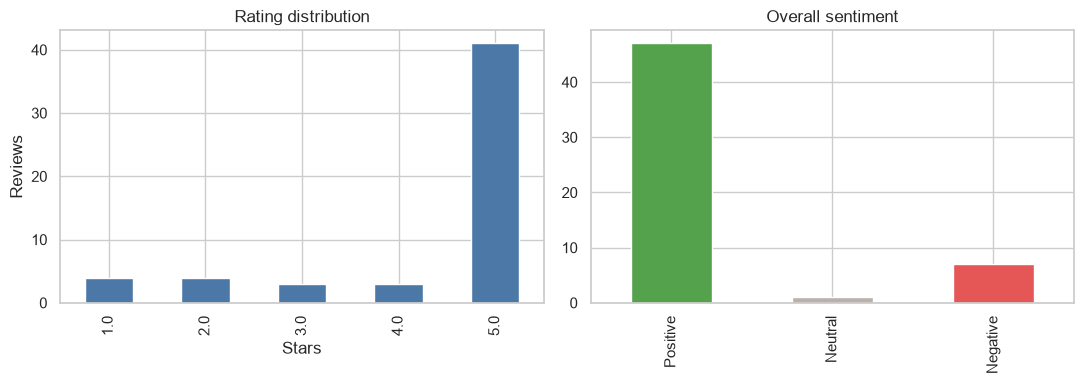

polarity,Neg,Pos,mentions,net_score
aspect,,,,
Value for Money,3,16,19,0.68
Display & Picture Quality,2,17,19,0.79
Customer Service & Delivery,4,7,11,0.27
Performance,2,7,9,0.56
Ease of Use & Setup,1,7,8,0.75
Defects & Durability,5,3,8,-0.25
Design & Build Quality,0,7,7,1.00
Connectivity & Ports,3,2,5,-0.20
Controls & Ergonomics,2,1,3,-0.33


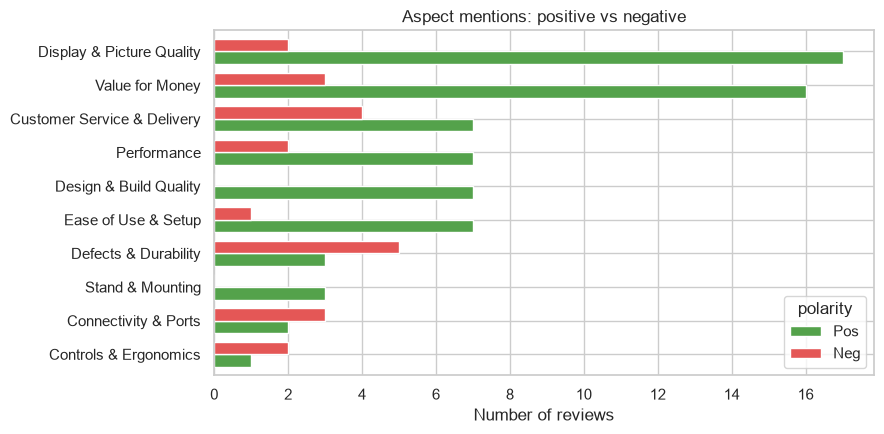

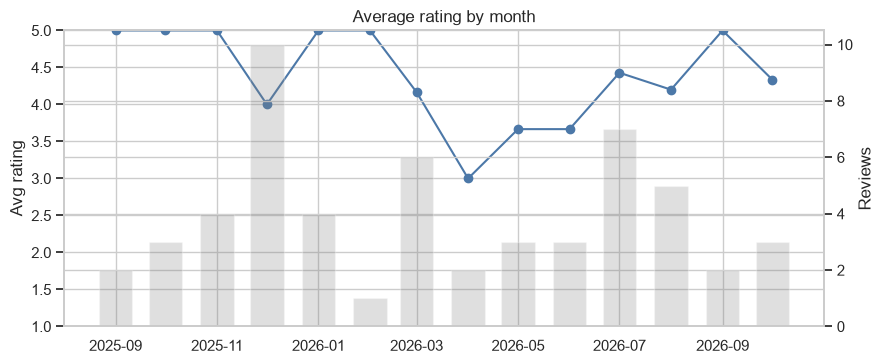

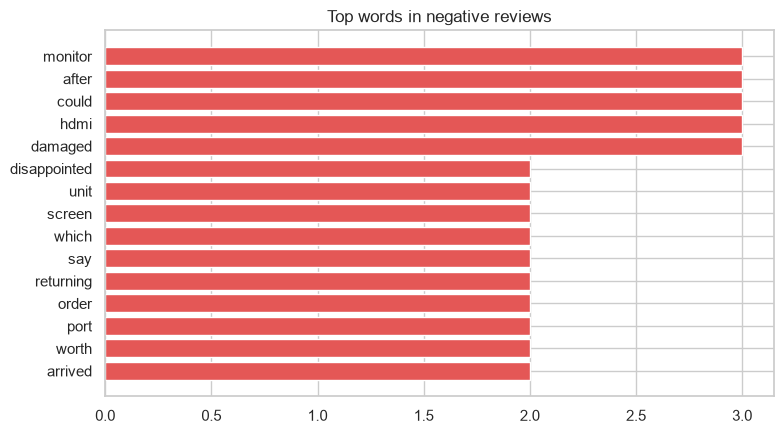

In [11]:
def save(fig_name):
    plt.tight_layout(); plt.savefig(CHART_DIR / f"{PREFIX}{fig_name}.png", dpi=160); plt.show()

# 1) Rating distribution + sentiment split
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
df["rating"].value_counts().reindex([1.0, 2.0, 3.0, 4.0, 5.0], fill_value=0).plot.bar(ax=ax[0], color="#4C78A8")
ax[0].set_title("Rating distribution"); ax[0].set_xlabel("Stars"); ax[0].set_ylabel("Reviews")
order = ["Positive", "Neutral", "Negative"]
colors = {"Positive": "#54A24B", "Neutral": "#BAB0AC", "Negative": "#E45756"}
df["overall_sentiment"].value_counts().reindex(order).plot.bar(ax=ax[1], color=[colors[o] for o in order])
ax[1].set_title("Overall sentiment"); ax[1].set_xlabel("")
save("01_rating_sentiment")

# 2) Aspect polarity table: what drives satisfaction / dissatisfaction
tags = df[["id", "sentiment_tags"]].explode("sentiment_tags").dropna()
tags[["aspect", "polarity"]] = tags["sentiment_tags"].str.extract(r"^(.*) \((Pos|Neg)\)$")
asp = tags.groupby(["aspect", "polarity"]).size().unstack(fill_value=0)
for c in ("Pos", "Neg"):
    if c not in asp: asp[c] = 0
asp["mentions"] = asp.Pos + asp.Neg
asp["net_score"] = ((asp.Pos - asp.Neg) / asp.mentions).round(2)
asp = asp.sort_values("mentions", ascending=False)
display(asp)

fig, ax = plt.subplots(figsize=(9, 4.5))
asp[["Pos", "Neg"]].sort_values("Pos").plot.barh(ax=ax, color=["#54A24B", "#E45756"], width=0.75)
ax.set_title("Aspect mentions: positive vs negative"); ax.set_xlabel("Number of reviews"); ax.set_ylabel("")
save("02_aspects")

# 3) Rating trend over time
t = df.dropna(subset=["date", "rating"]).copy()
t["month"] = pd.to_datetime(t["date"]).dt.to_period("M").dt.to_timestamp()
trend = t.groupby("month").agg(avg_rating=("rating", "mean"), reviews=("id", "count"))
if len(trend) > 1:
    fig, ax = plt.subplots(figsize=(9, 3.8))
    ax.plot(trend.index, trend.avg_rating, marker="o", color="#4C78A8"); ax.set_ylim(1, 5)
    ax.set_title("Average rating by month"); ax.set_ylabel("Avg rating")
    ax2 = ax.twinx(); ax2.bar(trend.index, trend.reviews, width=20, alpha=.25, color="grey"); ax2.set_ylabel("Reviews")
    save("03_trend")

# 4) Most frequent words in negative reviews
from collections import Counter
STOP = set("the a an and or but to of in on for with it is was this that i my me we you they be are as at have has had "
           "so very just not no too can will would from by if its it's i'm i've do did does one get got than then there "
           "out up all been were what when also really product".split())
def top_words(texts, k=15):
    words = re.findall(r"[a-z']{3,}", " ".join(texts).lower())
    return Counter(w for w in words if w not in STOP).most_common(k)
neg_words = top_words(df.loc[df.overall_sentiment == "Negative", "full_text"])
if neg_words:
    w, c = zip(*neg_words)
    fig, ax = plt.subplots(figsize=(8, 4.5)); ax.barh(w[::-1], c[::-1], color="#E45756")
    ax.set_title("Top words in negative reviews"); save("04_negative_words")

In [12]:
# Auto-generated insight summary: copy/paste/adapt into the report.
total = len(df)
pos_share = (df.overall_sentiment == "Positive").mean() * 100
neg_share = (df.overall_sentiment == "Negative").mean() * 100
print(f"({int(df.has_text.sum())} of {total} reviews contain written text; aspect insights come from those)")
print(f"Reviews analysed: {total} | avg rating: {df.rating.mean():.2f}/5 | positive {pos_share:.0f}% | negative {neg_share:.0f}%\n")

drivers_pos = asp.sort_values("Pos", ascending=False).head(3)
drivers_neg = asp.sort_values("Neg", ascending=False).head(3)
print("TOP SATISFACTION DRIVERS:")
for a, r in drivers_pos.iterrows():
    print(f"  - {a}: {int(r.Pos)} positive mentions ({r.Pos / max(r.mentions,1):.0%} of its mentions)")
print("\nTOP DISSATISFACTION DRIVERS:")
for a, r in drivers_neg.iterrows():
    print(f"  - {a}: {int(r.Neg)} negative mentions ({r.Neg / max(r.mentions,1):.0%} of its mentions)")

RECS = {
 "Display & Picture Quality": "Check panel quality control (brightness uniformity, dead areas) and publish clear display specs.",
 "Design & Build Quality": "Review materials and finish with the supplier; add QC checks for loose or cracked parts.",
 "Stand & Mounting": "Improve stand stability and height/tilt adjustment, or offer a VESA-compatible option.",
 "Controls & Ergonomics": "Move the power button to an accessible position and separate it from the on-screen menu toggle.",
 "Ease of Use & Setup": "Ship a quick-start card and clearer setup steps.",
 "Connectivity & Ports": "State the exact ports (for example HDMI 1.4 vs 2.0) and verify both ports in final QC.",
 "Performance": "Investigate lag, auto-sleep and power-on complaints with engineering.",
 "Value for Money": "Reassess pricing or bundle accessories to improve perceived value.",
 "Defects & Durability": "Run a root-cause review of dead pixels and screen faults; tighten warranty and return handling.",
 "Customer Service & Delivery": "Improve order accuracy at pickup, packaging and delivery tracking.",
}
print("\nRECOMMENDATIONS (linked to the top pain points):")
for a in drivers_neg.index:
    print(f"  - {a}: {RECS.get(a, 'Investigate the underlying reviews and address the root cause.')}")

low = df[(df.rating <= 2) & df.has_text]
if len(low):
    print(f"\nSample of low-rating reviews to quote in the report:")
    for t_ in low["review_text"].head(3):
        print("   *", t_[:160])

(42 of 55 reviews contain written text; aspect insights come from those)
Reviews analysed: 55 | avg rating: 4.33/5 | positive 85% | negative 13%

TOP SATISFACTION DRIVERS:
  - Display & Picture Quality: 17 positive mentions (89% of its mentions)
  - Value for Money: 16 positive mentions (84% of its mentions)
  - Customer Service & Delivery: 7 positive mentions (64% of its mentions)

TOP DISSATISFACTION DRIVERS:
  - Defects & Durability: 5 negative mentions (62% of its mentions)
  - Customer Service & Delivery: 4 negative mentions (36% of its mentions)
  - Connectivity & Ports: 3 negative mentions (60% of its mentions)

RECOMMENDATIONS (linked to the top pain points):
  - Defects & Durability: Run a root-cause review of dead pixels and screen faults; tighten warranty and return handling.
  - Customer Service & Delivery: Improve order accuracy at pickup, packaging and delivery tracking.
  - Connectivity & Ports: State the exact ports (for example HDMI 1.4 vs 2.0) and verify both ports in

## Part 8 - Anti-scraping challenges and solutions (copy into the report)

| Challenge | How it shows up | Mitigation (implemented / recommended) |
|---|---|---|
| **IP blocking / rate limiting** | HTTP 403/429, blank pages | *Implemented:* random 2-5 s delays, small request volume, exponential-back-off retries. *Recommended at scale:* session cool-downs; proxies only where the site's terms allow it |
| **CAPTCHA** | "Verify you are human" page | Slow down to avoid triggering; pause and let a human solve in the visible browser (`HEADLESS=False`); for production, prefer an official API/data partnership or a CAPTCHA-solving service **only where the site terms allow it** |
| **Dynamic JavaScript content** | Static HTML has no reviews | *Implemented:* Selenium waits + "Show More" clicks; Method B calls the same JSON endpoint the page uses |
| **Bot detection (observed)** | "Access Denied" page for the automated browser | **Respected, not bypassed:** the site's policy was honoured; public reviews were collected through normal browsing and parsed offline. For scale use an official API or a licensed data feed |
| **Layout changes** | Selectors return nothing | *Implemented:* ordered fallback selectors, regex-based rating extraction, selector-inspector helper; add monitoring that alerts when parsed rows drop |
| **Transient failures / timeouts** | Random exceptions mid-run | *Implemented:* `@retry` decorator, per-view try/except, checkpoint save of raw data |
| **Legal / ethical** | ToS, privacy | *Implemented:* robots.txt check, public data only, no login, no personal data beyond the public display name, throttled traffic. Always re-read the Terms of Use before large-scale collection |

**Limitations:** lexicon-based sentiment (VADER) can miss sarcasm and domain slang; aspect detection is keyword-driven; the sample is limited to what the site exposes publicly.
**Next steps:** fine-tune a transformer on labelled reviews, use a zero-shot/LLM aspect extractor, and schedule periodic scrapes for trend monitoring.